# Fase A — Análisis Exploratorio de Datos (EDA)
**Proyecto 2 y 3 · Introducción a la Ciencia de los Datos** — Dataset: *Siniestros Viales — Cali (Datos Abiertos, Secretaría de Movilidad), 2016–2024*

**Grupo #5:** Juan Alejandro Urrego (2569068) · Mariana De Los Ángeles Viera (2569104) · Anderson Gómez (2266242) · Juan Esteban Martinez Orobio (2569452) · Repositorio: `github.com/alejoneru/Ciencia_De_Datos_`

**Pregunta de negocio.** La Secretaría de Movilidad recibe cada año decenas de miles de reportes de incidentes viales, pero solo una parte termina siendo un siniestro con lesionados o fallecidos. **¿Qué características conocidas al momento del reporte (fecha, lugar, número y tipo de vehículos, clase de accidente, canal de reporte) permiten anticipar si un siniestro será *grave* (con lesionados o fallecidos) frente a uno de *solo daños*?** Responderla ayuda a priorizar el despacho de ambulancias y agentes, y a enfocar campañas de seguridad vial en los actores y lugares de mayor riesgo.

## 0. Continuidad con el Proyecto 1
En el Proyecto 1 (Fase A, 15-sep-2026) el grupo eligió este mismo dataset y diseñó una **bodega en modelo estrella**: `FACT_SINIESTRO` conectada a `DIM_TIEMPO`, `DIM_LUGAR`, `DIM_VIA` y `DIM_ACTOR`, con la gravedad (*leve / grave / mortal*) como variable objetivo de clasificación. Ese diseño se hizo a partir de la ficha del catálogo, y su sección 7 dejó **validaciones pendientes** sobre el CSV real. Este proyecto las resuelve y adapta el diseño a lo que el archivo realmente trae:

| Supuesto del P1 | Lo que trae el CSV real | Cómo se adapta en P2/P3 |
|---|---|---|
| ~90 000 registros | 371 003 reportes; 124 889 siniestros confirmados (el resto son reportes *negativos*) | Se modelan los 124 889 confirmados |
| Gravedad leve / grave / mortal | Solo daños / Con lesionado / Con fallecido | Equivalencia directa: leve = solo daños, grave = con lesionado, mortal = con fallecido. Se modela binaria (grave+mortal vs leve) y multiclase (3 niveles) |
| `DIM_LUGAR`: comuna, barrio, zona | Solo dirección en texto libre | `DIM_LUGAR` por dirección normalizada (intersección / clínica / otro); comuna y barrio = *No disponible* |
| `DIM_VIA`: tipo, clase, superficie | No existen como columnas | `tipo_via` extraído de la dirección (Calle, Carrera, Avenida…); clase y superficie = *No disponible* |
| `DIM_ACTOR`: tipo de actor, género, edad | Solo la lista de vehículos involucrados | `DIM_ACTOR` como perfil de vehículos (actor más vulnerable y vehículo más pesado); género y edad = *No disponible* |
| `DIM_TIEMPO` con posible hora | Solo fecha (sin hora) | `DIM_TIEMPO` en grano diario, con los mismos atributos del P1 |
| Grano: un actor por fila | Una fila por siniestro (`Código`) | Grano **siniestro**; `id_siniestro` sigue siendo la dimensión degenerada |

**Trazabilidad con los objetivos analíticos del P1**
- *Clasificar gravedad (leve/grave/mortal)* → Fase C: modelos binarios (grave vs leve) **y** un modelo multiclase de 3 niveles.
- *Segmentar barrios por perfil de riesgo* → como no hay barrio, se segmentan **intersecciones** (la unidad geográfica más fina disponible) con K-Means.
- *Predecir probabilidad de accidente por comuna-hora* → no es posible sin comuna ni hora; se analiza el riesgo por **día de la semana y mes** (calendario de la sección 6) y se deja como mejora futura cruzando con otras fuentes.

**Estructura del notebook**
0. Continuidad con el Proyecto 1
1. Carga del dataset con pandas y vista general
2. Preparación mínima para explorar (fechas, variables numéricas derivadas) y reconstrucción del modelo estrella del P1
3. Histogramas de variables numéricas
4. Boxplots para detectar outliers
5. Heatmaps de correlación (Pearson y Spearman)
6. Gráficos adicionales (líneas, barras, Pareto, heatmap calendario)
7. Resumen de hallazgos de negocio

In [1]:
# Librerías de análisis y visualización
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Estilo común para todas las figuras del proyecto
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "axes.labelsize": 10})
COLOR_GRAVE, COLOR_DANOS, COLOR_NEUTRO = "#C0392B", "#2E86C1", "#5D6D7E"

# Rutas: el CSV se toma de la variable de entorno DATA_PATH (ver .env.example)
RUTA_DATOS = Path(os.getenv("DATA_PATH", "../datos/siniestralidad_2016_2024.csv"))
RUTA_FIG = Path("figuras"); RUTA_FIG.mkdir(exist_ok=True)

def guardar(fig, nombre):
    """Guarda una figura en entrega/figuras con nombre consistente."""
    fig.savefig(RUTA_FIG / f"{nombre}.png", bbox_inches="tight")

## 1. Carga del dataset
El archivo viene separado por `;` y codificado en **cp1252** (Windows). Se carga todo como texto para no perder información en la conversión de tipos; las conversiones se hacen de forma explícita después.

In [2]:
# Carga cruda: todo como texto para inspeccionar sin conversiones implícitas
df_raw = pd.read_csv(RUTA_DATOS, sep=";", encoding="cp1252", dtype=str)
print("Dimensiones:", df_raw.shape)
print("Columnas originales:", df_raw.columns.tolist())
df_raw.head()

Dimensiones: (371003, 10)
Columnas originales: ['Código', 'Fecha', 'Tipo confirmado', 'Dirección reporte', 'Tipo clase de accidente', 'Tipo clase de accidente.1', 'Tipo confirmado.1', 'Medio de reporte', 'Numero vehículos', 'Tipo de vehículos implicados']


,Código,Fecha,Tipo confirmado,Dirección reporte,Tipo clase de accidente,Tipo clase de accidente.1,Tipo confirmado.1,Medio de reporte,Numero vehículos,Tipo de vehículos implicados
0,96159,1/01/2016,Solo daños,Carrera 56 Con Calle 1 A,.,.,Solo Da?os,RADIO,2,MOTOCICLETA
1,96160,1/01/2016,Negativo,Calle 72 O Con Carrera 28 H,.,.,Negativo,RADIO,.,.
2,96161,1/01/2016,Con lesionado,Carrera 94 Con Calle 4 C,ATROPELLO,ATROPELLO,Por Atropello,TELEF?NICO 127,2,MOTOCICLETA
3,96162,1/01/2016,Con lesionado,Carrera 8 A Con Calle 44,VOLCAMIENTO,VOLCAMIENTO,Por Volcamiento,RADIO,1,MOTOCICLETA
4,96163,1/01/2016,Negativo,Carrera 28 H Con Calle 72 M,.,.,Negativo,TELEF?NICO 127,.,.


In [3]:
# Las columnas "Tipo clase de accidente" y "Tipo confirmado" vienen repetidas en el encabezado.
# Se renombran a nombres cortos y sin tildes para trabajar cómodamente.
df_raw.columns = ["codigo", "fecha", "tipo_confirmado", "direccion", "clase_accidente",
                  "clase_accidente_dup", "detalle_confirmado", "medio_reporte",
                  "num_vehiculos", "vehiculos_implicados"]
iguales = (df_raw["clase_accidente"] == df_raw["clase_accidente_dup"]).mean()
print(f"'clase_accidente' y su duplicado coinciden en el {iguales:.4%} de las filas")
df_raw.info()

'clase_accidente' y su duplicado coinciden en el 99.9997% de las filas
<class 'pandas.DataFrame'>
RangeIndex: 371003 entries, 0 to 371002
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   codigo                371002 non-null  str  
 1   fecha                 371002 non-null  str  
 2   tipo_confirmado       371002 non-null  str  
 3   direccion             189410 non-null  str  
 4   clase_accidente       371002 non-null  str  
 5   clase_accidente_dup   371002 non-null  str  
 6   detalle_confirmado    371003 non-null  str  
 7   medio_reporte         371003 non-null  str  
 8   num_vehiculos         371003 non-null  str  
 9   vehiculos_implicados  371003 non-null  str  
dtypes: str(10)
memory usage: 50.6 MB


In [4]:
# Calidad general: valores nulos explícitos (NaN) y nulos "disfrazados" con un punto '.'
resumen = pd.DataFrame({
    "nulos_NaN": df_raw.isna().sum(),
    "nulos_punto": (df_raw == ".").sum(),
})
resumen["%_faltante_total"] = ((resumen.nulos_NaN + resumen.nulos_punto) / len(df_raw) * 100).round(1)
resumen["valores_unicos"] = df_raw.nunique()
resumen

,nulos_NaN,nulos_punto,%_faltante_total,valores_unicos
codigo,1,0,0.0,370998
fecha,1,0,0.0,3229
tipo_confirmado,1,2,0.0,7
direccion,181593,2093,49.5,65335
clase_accidente,1,325257,87.7,15
clase_accidente_dup,1,325257,87.7,15
detalle_confirmado,0,23389,6.3,22
medio_reporte,0,288099,77.7,18
num_vehiculos,0,194424,52.4,13
vehiculos_implicados,0,222214,59.9,844


**Insight:** El dataset tiene 371.003 reportes y 10 columnas, todas de texto. El faltante real está *disfrazado*: la base usa un punto `.` en lugar de vacío, por lo que `clase_accidente` y `medio_reporte` están vacías en más del 75 % de los reportes. Antes de cualquier modelo hay que tratar el `.` como nulo; si no, un algoritmo lo tomaría como una categoría "real" y aprendería del vacío.

In [5]:
# Distribución del resultado confirmado de cada reporte
tipo = df_raw["tipo_confirmado"].str.strip().replace({"Solo Daños": "Solo daños"})
tabla_tipo = tipo.value_counts().to_frame("reportes")
tabla_tipo["%"] = (tabla_tipo.reportes / tabla_tipo.reportes.sum() * 100).round(2)
tabla_tipo

,reportes,%
tipo_confirmado,,
Negativo,246110,66.34
Solo daños,74030,19.95
Con lesionado,47500,12.80
Con fallecido,2907,0.78
Con fallecido (Foraneo),453,0.12
.,2,0.00


**Insight:** Dos de cada tres reportes (66 %) resultan **negativos**: el incidente no se confirma como siniestro. De los ~125 mil siniestros confirmados, el 41 % tiene lesionados o fallecidos. Esto define el alcance del modelo: se trabajará sobre siniestros confirmados para distinguir *grave* (lesionado/fallecido) de *solo daños*.

## 2. Preparación mínima para explorar
Solo para el EDA se derivan variables numéricas (la limpieza formal y justificada está en la Fase B): fecha, año, mes, día de la semana, número de vehículos, conteos por tipo de vehículo y un indicador de gravedad.

In [6]:
# Conversión de fecha y variables de calendario
df = df_raw.copy()
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y", errors="coerce")
df = df.dropna(subset=["fecha"])                      # 1 fila totalmente vacía al final del archivo
df["tipo_confirmado"] = df["tipo_confirmado"].str.strip().replace({"Solo Daños": "Solo daños"})
df["anio"], df["mes"] = df.fecha.dt.year, df.fecha.dt.month
df["dia_semana"] = df.fecha.dt.dayofweek               # 0 = lunes ... 6 = domingo

# Número de vehículos: '.' -> NaN y '1.' -> 1
df["num_vehiculos"] = pd.to_numeric(df["num_vehiculos"].str.replace(".", "", regex=False)
                                    .replace("", np.nan), errors="coerce")

# Familias de vehículos (regex sobre la lista separada por comas)
FAMILIAS = {
    "n_motos": r"^(MOTOCICLETA|MOTOCICLO|MOTOCARRO|MOTOTRICICLO|CUATRIMOTO|TRICIMOTO|CICLOMOTOR)$",
    "n_livianos": r"^(AUTOMOVIL|AUTOMOVIL ?TURISMO|CAMPERO|CAMIONETA|VAN|MINI +VAN|AMBULANCIA.*)$",
    "n_transporte_publico": r"^(BUS.*|BUSETA|MICROBUS|MINIBUS)$",
    "n_pesados": r"^(CAMION.*|VOLQUETA|TRACTO.*|GRUA|REMOLQUE|SEMIREMOLQUE|APLANADORA|COMPACTADORA|"
                 r"BARREDORA|MINICARGADOR|MAQ.*|EXCAVADORA|CARGADORA.*|CARRETILLA.*|TRITURADORA|"
                 r"ABONADORA|PRENSA.*|CORTADORA)$",
    "n_bicicletas": r"^(BICICLETA)$",
}

In [7]:
def contar_familias(texto):
    """Cuenta cuántos vehículos de cada familia aparecen en 'vehiculos_implicados'."""
    if pd.isna(texto) or texto.strip() in (".", ""):
        return [np.nan] * len(FAMILIAS)
    items = [t.strip().upper() for t in texto.replace('"', "").split(",") if t.strip()]
    return [sum(bool(re.match(p, it)) for it in items) for p in FAMILIAS.values()]

conteos = pd.DataFrame(df["vehiculos_implicados"].map(contar_familias).tolist(),
                       columns=list(FAMILIAS), index=df.index)
df = pd.concat([df, conteos], axis=1)

# Subconjunto de siniestros confirmados y variable objetivo binaria
CONFIRMADOS = ["Solo daños", "Con lesionado", "Con fallecido", "Con fallecido (Foraneo)"]
sin = df[df.tipo_confirmado.isin(CONFIRMADOS)].copy()
sin["es_grave"] = (sin.tipo_confirmado != "Solo daños").astype(int)
sin["es_fallecido"] = sin.tipo_confirmado.str.startswith("Con fallecido").astype(int)
print(f"Siniestros confirmados: {len(sin):,} | % graves: {sin.es_grave.mean():.1%} | % con fallecido: {sin.es_fallecido.mean():.2%}")

Siniestros confirmados: 124,890 | % graves: 40.7% | % con fallecido: 2.69%


In [8]:
# Tablas agregadas que se usan en varios gráficos
diario = df.groupby("fecha").agg(reportes=("codigo", "size"))
diario = diario.join(sin.groupby("fecha").agg(siniestros=("codigo", "size"), graves=("es_grave", "sum"))).fillna(0)
diario["anio"] = diario.index.year

# Concentración por intersección (dirección normalizada a mayúsculas)
dir_norm = sin["direccion"].str.upper().str.strip()
por_dir = dir_norm[dir_norm.notna() & (dir_norm != ".")].value_counts()
print("Direcciones distintas con siniestro:", len(por_dir))
print(diario.describe().round(1))

Direcciones distintas con siniestro: 23489
       reportes  siniestros  graves    anio
count    3229.0      3229.0  3229.0  3229.0
mean      114.9        38.7    15.8  2019.9
std        59.8        21.6     6.2     2.5
min         1.0         0.0     0.0  2016.0
25%        60.0        18.0    11.0  2018.0
50%       107.0        37.0    15.0  2020.0
75%       169.0        54.0    20.0  2022.0
max       298.0       116.0    43.0  2024.0


### 2.1 Reconstrucción del modelo estrella del Proyecto 1 con los datos reales
Se construyen las tablas diseñadas en el P1 aplicando sus reglas: llaves subrogadas `sk_*`, un registro por defecto **`-1 / "Desconocido"`** en cada dimensión para los faltantes y atributos *"No disponible"* cuando la fuente no los trae. El dataset analítico de este proyecto es el resultado de unir el hecho con sus dimensiones.

In [9]:
def actor(r):
    """Clasifica el siniestro según el actor vial más vulnerable involucrado (atributo de DIM_ACTOR)."""
    if r.n_bicicletas > 0: return "Con bicicleta"
    if r.n_motos > 0: return "Con motocicleta"
    if r.n_pesados > 0: return "Con vehículo pesado"
    if r.n_transporte_publico > 0: return "Con transporte público"
    if r.n_livianos > 0: return "Solo livianos"
    return "Sin dato de vehículos"
sin["actor"] = sin[list(FAMILIAS)].fillna(0).apply(actor, axis=1)
sin["direccion_norm"] = dir_norm.where(dir_norm.notna() & (dir_norm != "."))
sin["tipo_via"] = sin["direccion_norm"].str.extract(r"^(CALLE|CARRERA|AVENIDA|TRANSVERSAL|DIAGONAL|AUTOPISTA|VIA)")[0].str.title()

def dimension(datos, columnas, nombre_sk):
    """Crea una dimensión con llave subrogada y el registro por defecto -1 'Desconocido' (regla del P1)."""
    dim = datos[columnas].drop_duplicates().dropna(how="all").reset_index(drop=True)
    dim.insert(0, nombre_sk, range(1, len(dim) + 1))
    defecto = pd.DataFrame([{nombre_sk: -1, **{c: "Desconocido" for c in columnas}}])
    return pd.concat([defecto, dim], ignore_index=True)

# DIM_TIEMPO: mismos atributos del P1 (grano diario)
MESES = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
fechas = pd.DataFrame({"fecha": sorted(sin.fecha.unique())})
dim_tiempo = fechas.assign(anio=fechas.fecha.dt.year, mes=fechas.fecha.dt.month,
                           nombre_mes=fechas.fecha.dt.month.map(lambda m: MESES[m - 1]),
                           trimestre=fechas.fecha.dt.quarter,
                           dia_semana=fechas.fecha.dt.dayofweek.map(lambda d: DIAS[d]),
                           es_fin_de_semana=(fechas.fecha.dt.dayofweek >= 5).astype(int))
dim_tiempo.insert(0, "sk_tiempo", dim_tiempo.fecha.dt.strftime("%Y%m%d").astype(int))   # llave inteligente AAAAMMDD

# DIM_LUGAR adaptada: la dirección reemplaza a comuna/barrio (no existen en la fuente)
lugar = sin[["direccion_norm"]].assign(
    tipo_lugar=np.select([sin.direccion_norm.str.contains(" CON ", na=False),
                          sin.direccion_norm.str.contains("CLINICA|HOSPITAL|HUV|IPS|CRISTO REY|IMBANACO|LILI", na=False)],
                         ["Intersección", "Centro de salud"], "Otro"))
dim_lugar = dimension(lugar.dropna(subset=["direccion_norm"]), ["direccion_norm", "tipo_lugar"], "sk_lugar")
dim_lugar = dim_lugar.assign(comuna="No disponible", barrio="No disponible", ciudad="Cali", zona="No disponible")

# DIM_VIA: tipo de vía extraído de la dirección; clase y superficie no existen en la fuente
dim_via = dimension(sin, ["tipo_via"], "sk_via").assign(clase_via="No disponible", superficie="No disponible")

# DIM_ACTOR adaptada: perfil de vehículos en vez de persona (no hay género ni edad)
dim_actor = dimension(sin, ["actor"], "sk_actor").rename(columns={"actor": "tipo_actor_vial"})
dim_actor = dim_actor.assign(genero="No disponible", rango_edad="No disponible")

In [10]:
# FACT_SINIESTRO: grano = un siniestro confirmado; gravedad con la nomenclatura del P1
GRAVEDAD_P1 = {"Solo daños": "leve", "Con lesionado": "grave", "Con fallecido": "mortal", "Con fallecido (Foraneo)": "mortal"}
fact = (sin.reset_index(drop=True)
        .merge(dim_lugar[["sk_lugar", "direccion_norm"]], on="direccion_norm", how="left")
        .merge(dim_via[["sk_via", "tipo_via"]], on="tipo_via", how="left")
        .merge(dim_actor[["sk_actor", "tipo_actor_vial"]], left_on="actor", right_on="tipo_actor_vial", how="left"))
fact_siniestro = pd.DataFrame({
    "sk_fact_siniestro": range(1, len(fact) + 1),
    "fk_tiempo": fact.fecha.dt.strftime("%Y%m%d").astype(int),
    "fk_lugar": fact.sk_lugar.fillna(-1).astype(int),
    "fk_via": fact.sk_via.fillna(-1).astype(int),
    "fk_actor": fact.sk_actor.fillna(-1).astype(int),
    "id_siniestro": fact.codigo,                                       # dimensión degenerada
    "gravedad_siniestro": fact.tipo_confirmado.map(GRAVEDAD_P1),       # leve / grave / mortal
    "condicion_resultado": fact.tipo_confirmado.map({"Solo daños": "ileso", "Con lesionado": "herido"}).fillna("fallecido"),
    "num_vehiculos": fact.num_vehiculos,                               # medida (reemplaza a edad_actor)
    "cantidad_siniestros": 1,                                          # medida aditiva
    "es_fatal": fact.tipo_confirmado.str.startswith("Con fallecido").astype(int)})
tamanos = pd.Series({"FACT_SINIESTRO": len(fact_siniestro), "DIM_TIEMPO": len(dim_tiempo), "DIM_LUGAR": len(dim_lugar),
                     "DIM_VIA": len(dim_via), "DIM_ACTOR": len(dim_actor)}, name="filas")
print(tamanos.to_string())
print("\n% de hechos con registro por defecto (-1):",
      fact_siniestro[["fk_lugar", "fk_via", "fk_actor"]].eq(-1).mean().round(3).to_dict())
fact_siniestro.head()

FACT_SINIESTRO    124890
DIM_TIEMPO          3227
DIM_LUGAR          23490
DIM_VIA                8
DIM_ACTOR              7

% de hechos con registro por defecto (-1): {'fk_lugar': 0.564, 'fk_via': 0.592, 'fk_actor': 0.0}


,sk_fact_siniestro,fk_tiempo,fk_lugar,fk_via,fk_actor,id_siniestro,gravedad_siniestro,condicion_resultado,num_vehiculos,cantidad_siniestros,es_fatal
0,1,20160101,1,1,1,96159,leve,ileso,2.0,1,0
1,2,20160101,2,1,1,96161,grave,herido,2.0,1,0
2,3,20160101,3,1,1,96162,grave,herido,1.0,1,0
3,4,20160101,4,1,1,96164,leve,ileso,2.0,1,0
4,5,20160101,5,1,2,96167,grave,herido,2.0,1,0


In [11]:
# Validaciones de integridad del modelo estrella (pendientes de la sección 7 del P1)
assert fact_siniestro.id_siniestro.is_unique or fact_siniestro.id_siniestro.duplicated().sum() <= 1, "id_siniestro duplicado"
assert fact_siniestro.fk_tiempo.isin(dim_tiempo.sk_tiempo).all()
assert fact_siniestro.fk_lugar.isin(dim_lugar.sk_lugar).all() and fact_siniestro.fk_via.isin(dim_via.sk_via).all()
assert fact_siniestro.fk_actor.isin(dim_actor.sk_actor).all()
print("Duplicados de id_siniestro en el hecho:", fact_siniestro.id_siniestro.duplicated().sum(),
      "(el único caso, código 350723, se elimina en la Fase B)")
print("Integridad referencial OK: todas las llaves foráneas existen en su dimensión")
dim_actor

Duplicados de id_siniestro en el hecho: 1 (el único caso, código 350723, se elimina en la Fase B)
Integridad referencial OK: todas las llaves foráneas existen en su dimensión


,sk_actor,tipo_actor_vial,genero,rango_edad
0,-1,Desconocido,No disponible,No disponible
1,1,Con motocicleta,No disponible,No disponible
2,2,Sin dato de vehículos,No disponible,No disponible
3,3,Solo livianos,No disponible,No disponible
4,4,Con vehículo pesado,No disponible,No disponible
5,5,Con transporte público,No disponible,No disponible
6,6,Con bicicleta,No disponible,No disponible


In [12]:
# Consulta tipo "estrella" (equivalente a un SELECT ... JOIN ... GROUP BY de la Fase C del P1):
# siniestros y fallecidos por año y trimestre, usando FACT_SINIESTRO + DIM_TIEMPO
consulta = (fact_siniestro.merge(dim_tiempo, left_on="fk_tiempo", right_on="sk_tiempo")
            .groupby(["anio", "gravedad_siniestro"])["cantidad_siniestros"].sum().unstack(fill_value=0)[["leve", "grave", "mortal"]])
consulta["fallecidos_es_fatal"] = fact_siniestro.merge(dim_tiempo, left_on="fk_tiempo", right_on="sk_tiempo").groupby("anio")["es_fatal"].sum()
consulta["%_mortal"] = (consulta.mortal / consulta[["leve", "grave", "mortal"]].sum(axis=1) * 100).round(2)
consulta

gravedad_siniestro,leve,grave,mortal,fallecidos_es_fatal,%_mortal
anio,,,,,
2016,7936,8215,362,362,2.19
2017,9637,6985,394,394,2.32
2018,16428,6475,451,451,1.93
2019,17142,5974,392,392,1.67
2020,9438,4167,392,392,2.80
2021,7101,4175,374,374,3.21
2022,5464,4131,384,384,3.85
2023,566,3963,387,387,7.87
2024,318,3415,224,224,5.66


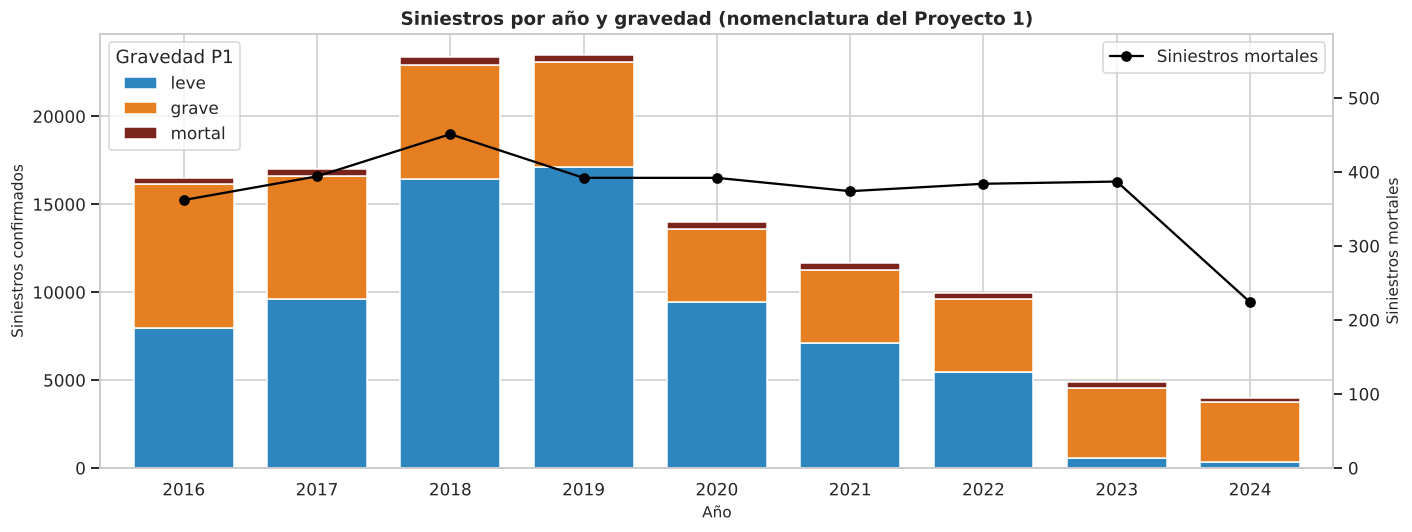

In [13]:
# Gráfico desde el modelo estrella: gravedad del P1 (leve/grave/mortal) por año
fig, ax1 = plt.subplots(figsize=(13, 5))
consulta[["leve", "grave", "mortal"]].plot(kind="bar", stacked=True, ax=ax1, width=.75,
                                          color=[COLOR_DANOS, "#E67E22", "#7B241C"])
ax1.set(title="Siniestros por año y gravedad (nomenclatura del Proyecto 1)", xlabel="Año", ylabel="Siniestros confirmados")
ax1.set_xticklabels(consulta.index, rotation=0); ax1.legend(title="Gravedad P1", loc="upper left")
ax2 = ax1.twinx(); ax2.plot(range(len(consulta)), consulta["mortal"], color="black", marker="o", label="Siniestros mortales")
ax2.set_ylabel("Siniestros mortales"); ax2.set_ylim(0, consulta["mortal"].max() * 1.3); ax2.grid(False); ax2.legend(loc="upper right")
fig.tight_layout(); guardar(fig, "a00_gravedad_p1_por_anio"); plt.show()

**Insight:** El modelo estrella del P1 funciona con los datos reales tras adaptarlo: 124 890 hechos, 3 227 fechas en `DIM_TIEMPO`, 23 490 lugares en `DIM_LUGAR` y 6 perfiles en `DIM_ACTOR`; el registro `-1 Desconocido` absorbe el 56 % de hechos sin dirección, tal como lo previó el P1. El hallazgo clave es que los siniestros **mortales son estables** (entre 362 y 451 por año de 2016 a 2023; 2024 está incompleto), mientras los leves se desploman en 2023: por eso el % mortal pasa de ≈2 % a 7,9 %. No es que la ciudad sea más letal, sino que los leves dejaron de registrarse; los mortales casi nunca dejan de reportarse y son la serie más confiable para comparar años. Para la Secretaría, la meta de reducir muertes no muestra avances en 8 años.

## 3. Histogramas de las variables numéricas

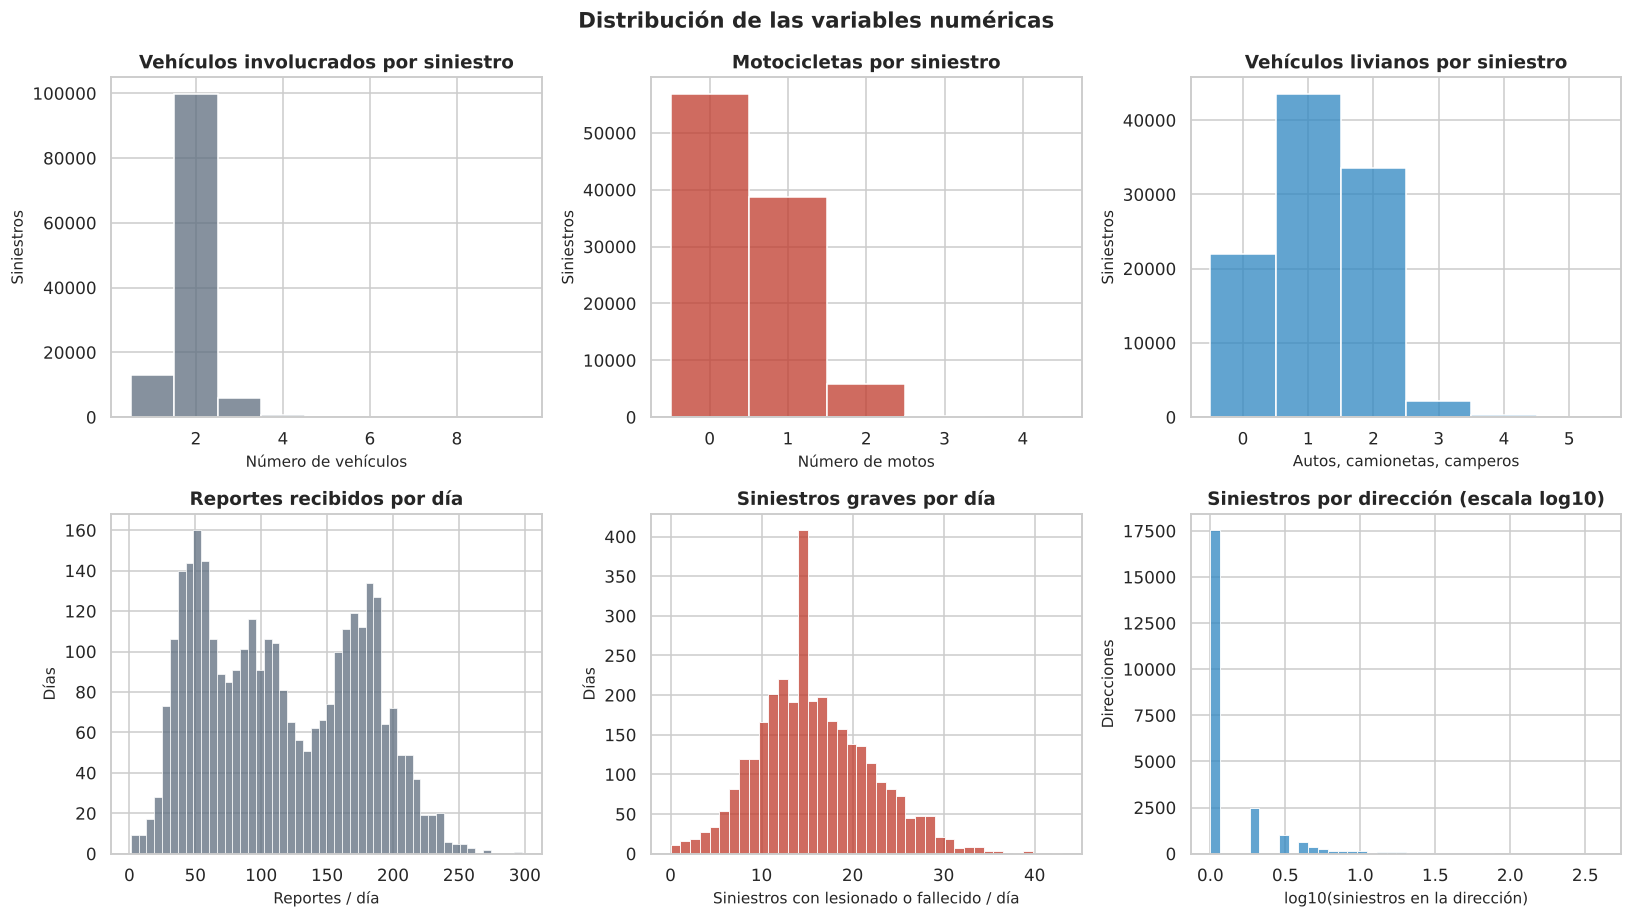

In [14]:
# Histogramas de las variables numéricas a nivel de siniestro y a nivel de día
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
sns.histplot(sin["num_vehiculos"].dropna(), discrete=True, ax=axes[0, 0], color=COLOR_NEUTRO)
axes[0, 0].set(title="Vehículos involucrados por siniestro", xlabel="Número de vehículos", ylabel="Siniestros")
sns.histplot(sin["n_motos"].dropna(), discrete=True, ax=axes[0, 1], color=COLOR_GRAVE)
axes[0, 1].set(title="Motocicletas por siniestro", xlabel="Número de motos", ylabel="Siniestros")
sns.histplot(sin["n_livianos"].dropna(), discrete=True, ax=axes[0, 2], color=COLOR_DANOS)
axes[0, 2].set(title="Vehículos livianos por siniestro", xlabel="Autos, camionetas, camperos", ylabel="Siniestros")
sns.histplot(diario["reportes"], bins=50, ax=axes[1, 0], color=COLOR_NEUTRO)
axes[1, 0].set(title="Reportes recibidos por día", xlabel="Reportes / día", ylabel="Días")
sns.histplot(diario["graves"], bins=40, ax=axes[1, 1], color=COLOR_GRAVE)
axes[1, 1].set(title="Siniestros graves por día", xlabel="Siniestros con lesionado o fallecido / día", ylabel="Días")
sns.histplot(np.log10(por_dir), bins=40, ax=axes[1, 2], color=COLOR_DANOS)
axes[1, 2].set(title="Siniestros por dirección (escala log10)", xlabel="log10(siniestros en la dirección)", ylabel="Direcciones")
fig.suptitle("Distribución de las variables numéricas", fontsize=14, fontweight="bold")
fig.tight_layout(); guardar(fig, "a01_histogramas"); plt.show()

In [15]:
# Asimetría (skewness) para cuantificar lo que muestran los histogramas
asim = pd.Series({
    "num_vehiculos": sin.num_vehiculos.skew(), "n_motos": sin.n_motos.skew(),
    "n_livianos": sin.n_livianos.skew(), "reportes_dia": diario.reportes.skew(),
    "graves_dia": diario.graves.skew(), "siniestros_por_direccion": por_dir.skew()}).round(2)
asim.to_frame("asimetria")

,asimetria
num_vehiculos,1.00
n_motos,0.87
n_livianos,0.15
reportes_dia,0.19
graves_dia,0.40
siniestros_por_direccion,21.24


**Insight:** El siniestro típico involucra **2 vehículos** y casi siempre al menos un automóvil; los casos de 4 o más vehículos son raros (< 1 %) y forman la cola derecha. La variable más sesgada es la de **siniestros por dirección** (asimetría muy alta): unas pocas intersecciones acumulan decenas o cientos de casos mientras la mayoría registra uno o dos, lo que anticipa la necesidad de una transformación logarítmica en la Fase B y justifica enfocar el control en "puntos negros". Los reportes diarios no forman una sola campana sino varios picos (≈50, ≈100 y ≈180 reportes/día): son distintas épocas de registro mezcladas, un cambio de nivel que se confirma en la serie de tiempo.

## 4. Boxplots para detectar outliers

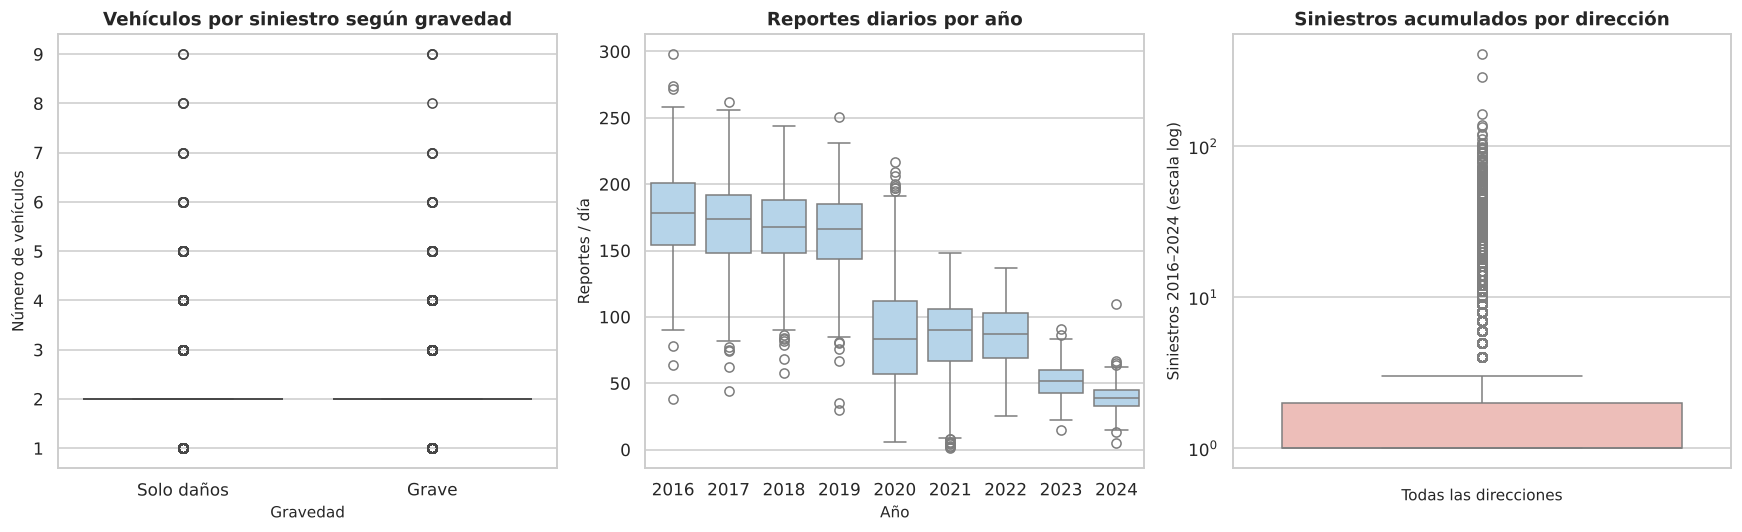

In [16]:
# Boxplots: número de vehículos por gravedad, reportes diarios por año y siniestros por dirección
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sin_plot = sin.assign(gravedad=sin.es_grave.map({0: "Solo daños", 1: "Grave"}))
sns.boxplot(data=sin_plot, x="gravedad", y="num_vehiculos", hue="gravedad", legend=False,
            palette={"Solo daños": COLOR_DANOS, "Grave": COLOR_GRAVE}, ax=axes[0])
axes[0].set(title="Vehículos por siniestro según gravedad", xlabel="Gravedad", ylabel="Número de vehículos")
sns.boxplot(data=diario.reset_index(), x="anio", y="reportes", color="#AED6F1", ax=axes[1])
axes[1].set(title="Reportes diarios por año", xlabel="Año", ylabel="Reportes / día")
sns.boxplot(y=por_dir.values, color="#F5B7B1", ax=axes[2])
axes[2].set_yscale("log")
axes[2].set(title="Siniestros acumulados por dirección", xlabel="Todas las direcciones", ylabel="Siniestros 2016–2024 (escala log)")
fig.tight_layout(); guardar(fig, "a02_boxplots"); plt.show()

In [17]:
# Cuantificación de outliers con la regla IQR (1.5 * rango intercuartílico)
def outliers_iqr(serie):
    """Devuelve límites IQR y cantidad/porcentaje de valores atípicos de una serie."""
    s = serie.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < li) | (s > ls)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "lim_inf": li, "lim_sup": ls, "n_outliers": n, "%": round(n / len(s) * 100, 2)})

pd.DataFrame({"num_vehiculos": outliers_iqr(sin.num_vehiculos),
              "reportes_dia": outliers_iqr(diario.reportes),
              "graves_dia": outliers_iqr(diario.graves),
              "siniestros_por_direccion": outliers_iqr(por_dir)}).T

,Q1,Q3,lim_inf,lim_sup,n_outliers,%
num_vehiculos,2.0,2.0,2.0,2.0,19604.0,16.41
reportes_dia,60.0,169.0,-103.5,332.5,0.0,0.00
graves_dia,11.0,20.0,-2.5,33.5,19.0,0.59
siniestros_por_direccion,1.0,2.0,-0.5,3.5,2455.0,10.45


In [18]:
# Promedio de vehículos y % de siniestros con 1 vehículo según gravedad
sin.groupby(sin.es_grave.map({0: "Solo daños", 1: "Grave"}))["num_vehiculos"].agg(
    promedio="mean", pct_un_vehiculo=lambda s: (s == 1).mean()).round(3)

,promedio,pct_un_vehiculo
es_grave,,
Grave,1.845,0.207
Solo daños,2.039,0.032


**Insight:** En `num_vehiculos` el 80 % de los casos tiene exactamente 2 vehículos, así que Q1 = Q3 = 2 y el IQR vale cero: la regla IQR marca como atípico *cualquier* siniestro que no sea de 2 vehículos (16 %), lo cual no tiene sentido de negocio. Por eso en la Fase B esta variable se trata con **Z-score** y los choques múltiples reales (hasta 16 vehículos) se acotan en lugar de eliminarse. Los siniestros graves involucran en promedio **menos vehículos** y los casos de 1 solo vehículo (atropellos, volcamientos, caídas de ocupante) representan el 21 % de los graves frente al 3 % de los de solo daños (promedio 1,85 vs 2,04 vehículos). El boxplot por año muestra la caída de los reportes diarios: de una mediana de ≈170 en 2016–2019 a ≈90 en 2020–2022 y ≈40–50 en 2023–2024. En direcciones, los atípicos son precisamente los puntos críticos de la ciudad: no se descartan, son la información más valiosa para la Secretaría.

## 5. Heatmaps de correlación (Pearson y Spearman)

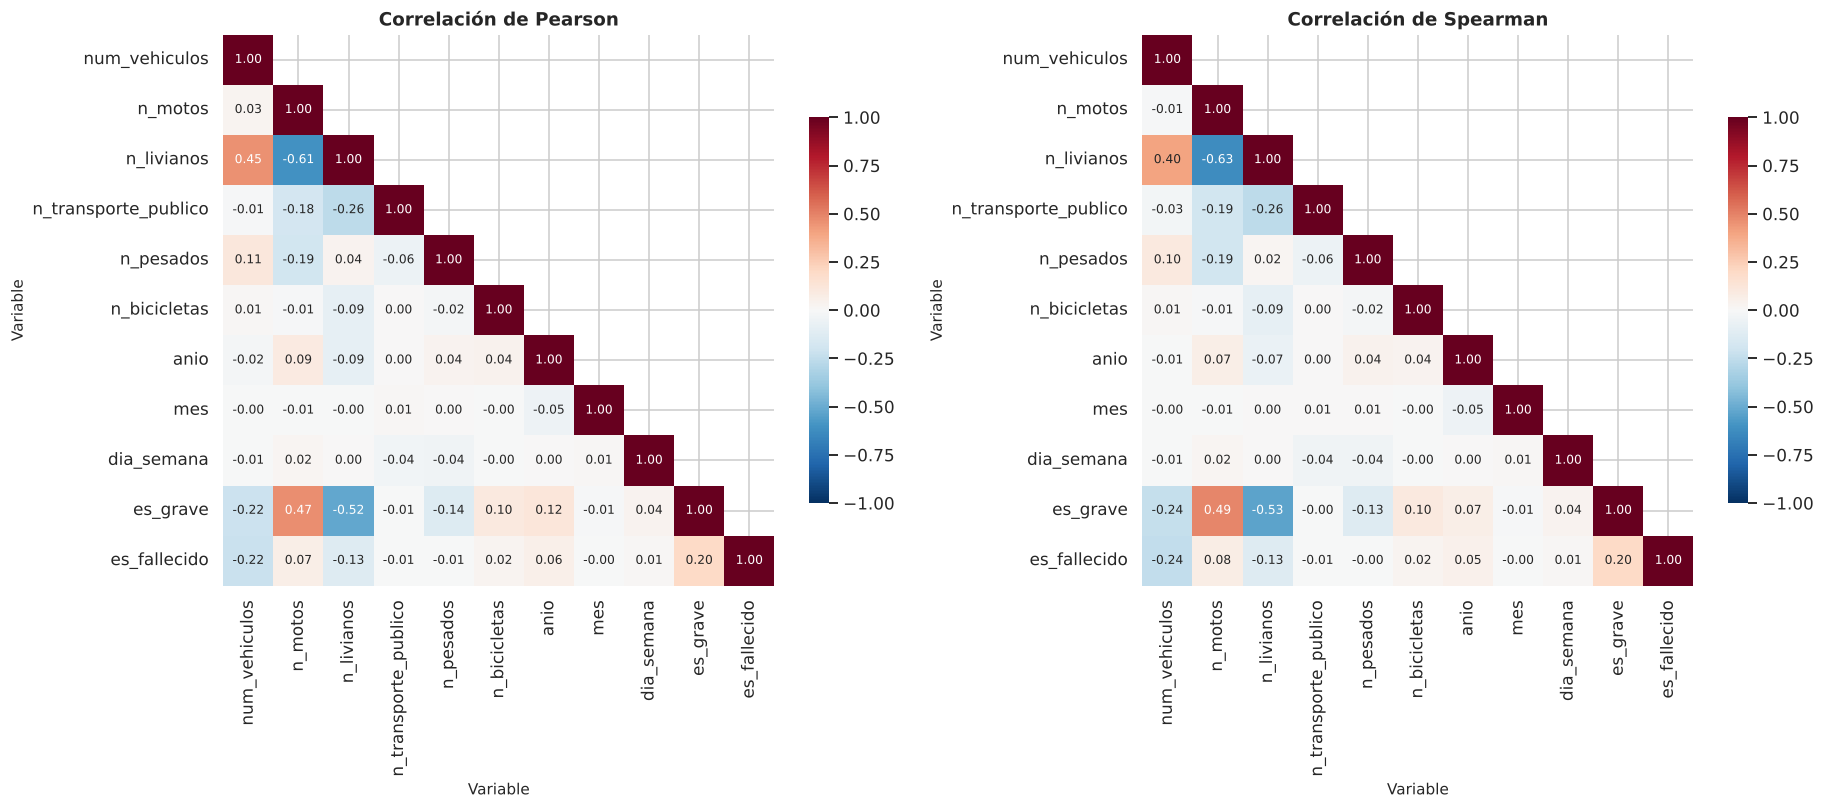

In [19]:
# Matriz de correlación sobre las variables numéricas a nivel de siniestro
num_cols = ["num_vehiculos", "n_motos", "n_livianos", "n_transporte_publico", "n_pesados",
            "n_bicicletas", "anio", "mes", "dia_semana", "es_grave", "es_fallecido"]
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = sin[num_cols].corr(method=metodo)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, cbar_kws={"shrink": .7}, ax=ax, annot_kws={"size": 8})
    ax.set(title=f"Correlación de {metodo.capitalize()}", xlabel="Variable", ylabel="Variable")
fig.tight_layout(); guardar(fig, "a03_correlaciones"); plt.show()

In [20]:
# Correlaciones de cada variable con la gravedad, lado a lado
pd.DataFrame({m: sin[num_cols].corr(method=m)["es_grave"] for m in ["pearson", "spearman"]}).drop(["es_grave"]).round(3).sort_values("spearman")

,pearson,spearman
n_livianos,-0.518,-0.533
num_vehiculos,-0.215,-0.240
n_pesados,-0.135,-0.132
mes,-0.009,-0.010
n_transporte_publico,-0.007,-0.002
dia_semana,0.039,0.038
anio,0.118,0.067
n_bicicletas,0.098,0.098
es_fallecido,0.201,0.201
n_motos,0.467,0.485


**Insight:** La variable que más se asocia con un siniestro grave es la **presencia de motocicletas** (Spearman ≈ +0,49), mientras que tener más **vehículos livianos** se asocia con *solo daños* (≈ −0,53): un choque entre carros rara vez deja heridos, uno con moto con frecuencia sí. Pearson y Spearman dan resultados muy parecidos, señal de que las relaciones son monótonas y no están dominadas por los valores extremos. El año también se correlaciona con la gravedad, pero eso refleja un cambio en qué se registra (menos casos de solo daños en 2023–2024), no que las vías sean más peligrosas.

## 6. Gráficos adicionales

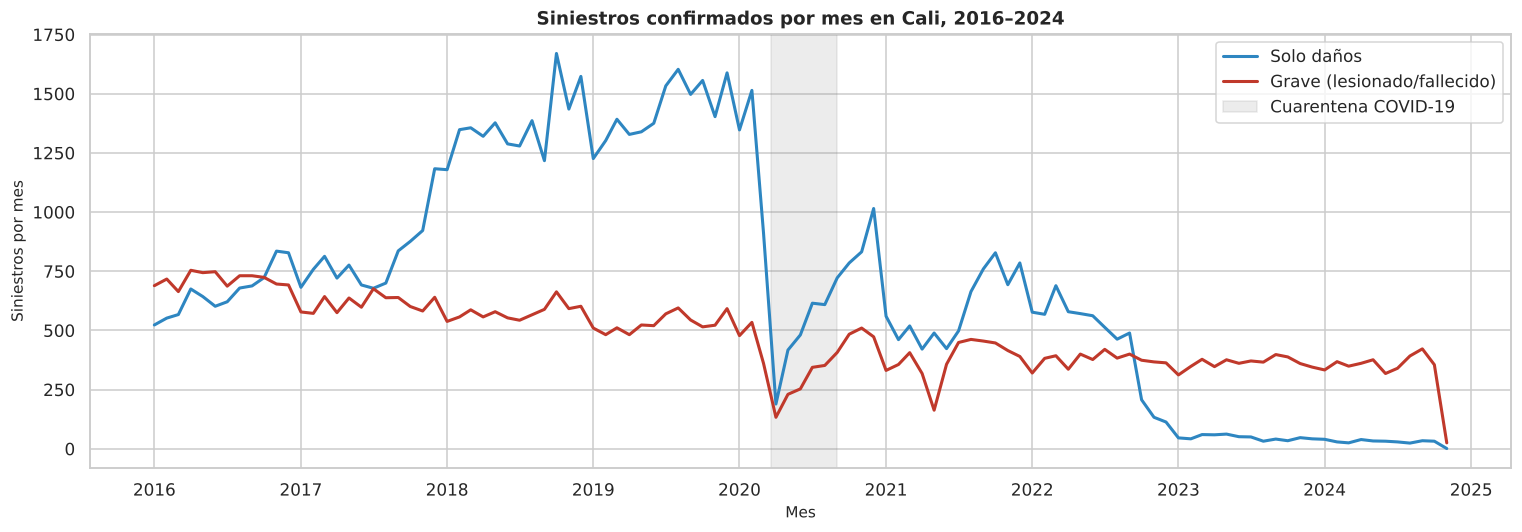

In [21]:
# (a) Serie de tiempo mensual: siniestros graves vs solo daños
mensual = sin.groupby([pd.Grouper(key="fecha", freq="MS"), "es_grave"]).size().unstack(fill_value=0)
mensual.columns = ["Solo daños", "Grave (lesionado/fallecido)"]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(mensual.index, mensual["Solo daños"], color=COLOR_DANOS, lw=2, label="Solo daños")
ax.plot(mensual.index, mensual["Grave (lesionado/fallecido)"], color=COLOR_GRAVE, lw=2, label="Grave (lesionado/fallecido)")
ax.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-08-31"), color="grey", alpha=.15, label="Cuarentena COVID-19")
ax.set(title="Siniestros confirmados por mes en Cali, 2016–2024", xlabel="Mes", ylabel="Siniestros por mes")
ax.legend(loc="upper right"); fig.tight_layout(); guardar(fig, "a04_serie_mensual"); plt.show()

**Insight:** Los siniestros **graves bajan de forma gradual**, de ≈700 al mes en 2016 a ≈350–400 en 2023–2024, con la caída puntual de la cuarentena de 2020. Los de *solo daños*, en cambio, se duplican en 2018–2019 y luego se desploman a finales de 2022 hasta casi desaparecer: un salto tan brusco indica un cambio en el protocolo de registro (choques simples resueltos con arreglo directo, sin reporte) más que una mejora real. El modelo debe incluir el año para no confundir este cambio administrativo con riesgo, y el último mes (nov-2024) está incompleto.

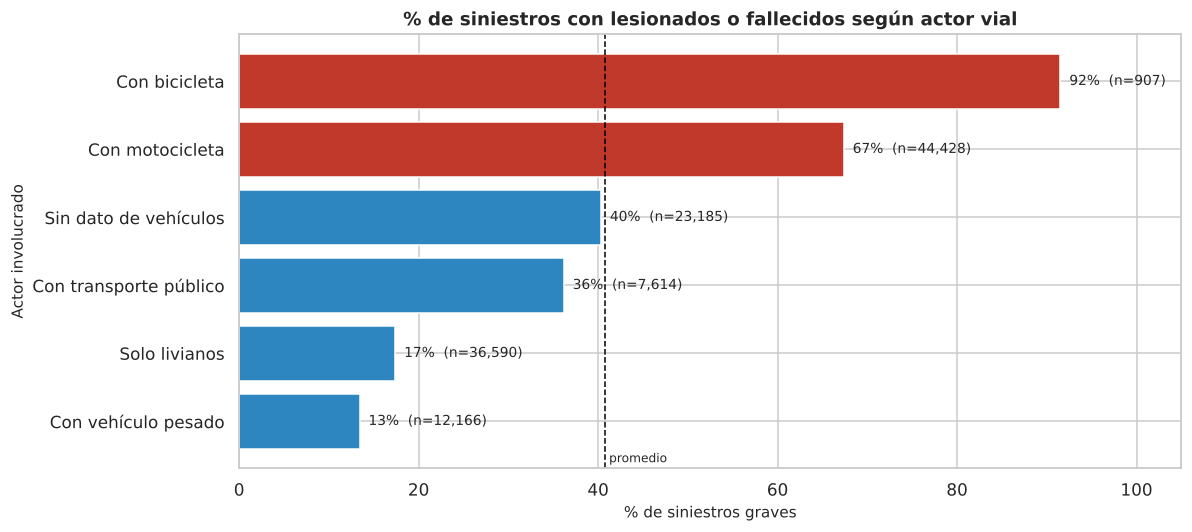

,siniestros,tasa_grave
actor,,
Con vehículo pesado,12166,0.134144
Solo livianos,36590,0.173927
Con transporte público,7614,0.361702
Sin dato de vehículos,23185,0.403149
Con motocicleta,44428,0.673742
Con bicicleta,907,0.915105


In [22]:
# (b) Tasa de gravedad según el actor vial (atributo tipo_actor_vial de DIM_ACTOR)
tasa = sin.groupby("actor").agg(siniestros=("es_grave", "size"), tasa_grave=("es_grave", "mean")).sort_values("tasa_grave")
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(tasa.index, tasa.tasa_grave * 100, color=[COLOR_GRAVE if v > .5 else COLOR_DANOS for v in tasa.tasa_grave])
for b, (v, n) in zip(bars, zip(tasa.tasa_grave, tasa.siniestros)):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{v:.0%}  (n={n:,})", va="center", fontsize=9)
ax.axvline(sin.es_grave.mean() * 100, ls="--", color="black", lw=1)
ax.text(sin.es_grave.mean() * 100 + .5, -0.6, "promedio", fontsize=8)
ax.set(title="% de siniestros con lesionados o fallecidos según actor vial", xlabel="% de siniestros graves", ylabel="Actor involucrado", xlim=(0, 105))
fig.tight_layout(); guardar(fig, "a05_gravedad_actor"); plt.show()
tasa

**Insight:** El actor vial involucrado es el predictor más claro de gravedad: cuando hay **bicicleta o motocicleta**, la mayoría de los siniestros deja lesionados o fallecidos, mientras que los choques **solo entre vehículos livianos** son casi siempre de solo daños. Para la Secretaría, esto respalda priorizar el despacho de ambulancia cuando el reporte menciona una moto o una bicicleta, y mantener las campañas de seguridad dirigidas a motociclistas.

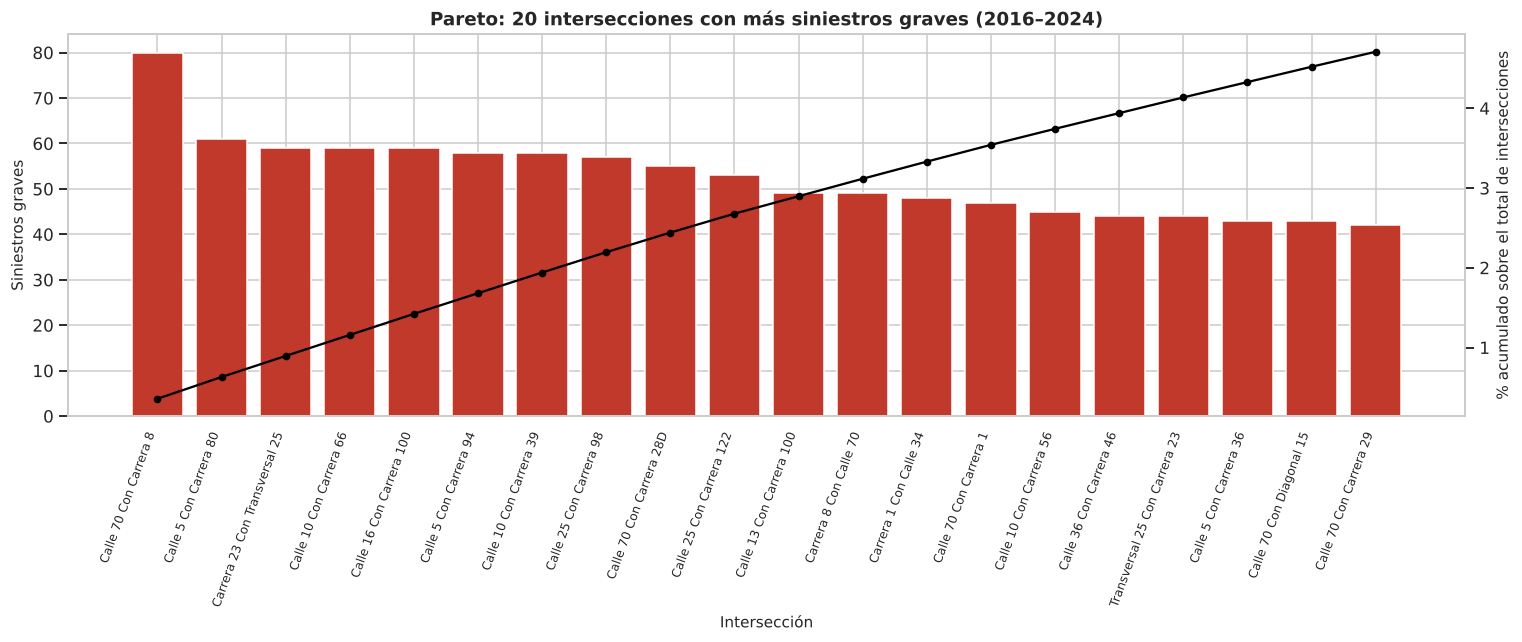

Intersecciones con al menos un siniestro grave: 10,483
El 10 % de intersecciones más críticas concentra el 46.0% de los siniestros graves


In [23]:
# (c) Pareto de intersecciones: ¿qué tanto se concentran los siniestros graves?
graves_dir = dir_norm[(sin.es_grave == 1) & dir_norm.notna() & (dir_norm != ".")]
graves_dir = graves_dir[graves_dir.str.contains(" CON ")].value_counts()   # solo intersecciones (excluye clínicas)
top = graves_dir.head(20)
acum = graves_dir.cumsum() / graves_dir.sum() * 100
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(range(len(top)), top.values, color=COLOR_GRAVE)
ax1.set_xticks(range(len(top))); ax1.set_xticklabels([t.title() for t in top.index], rotation=70, ha="right", fontsize=8)
ax1.set(title="Pareto: 20 intersecciones con más siniestros graves (2016–2024)", xlabel="Intersección", ylabel="Siniestros graves")
ax2 = ax1.twinx(); ax2.plot(range(len(top)), acum.head(20).values, color="black", marker="o", ms=4)
ax2.set_ylabel("% acumulado sobre el total de intersecciones"); ax2.grid(False)
fig.tight_layout(); guardar(fig, "a06_pareto_intersecciones"); plt.show()
p10 = int(len(graves_dir) * .10)
print(f"Intersecciones con al menos un siniestro grave: {len(graves_dir):,}")
print(f"El 10 % de intersecciones más críticas concentra el {graves_dir.head(p10).sum() / graves_dir.sum():.1%} de los siniestros graves")

**Insight:** Los siniestros graves se dispersan por miles de intersecciones, pero existe un núcleo de puntos críticos: el 10 % de las intersecciones con más casos concentra el 46 % de los siniestros graves con dirección registrada. Concentrar cámaras, semaforización y control en esas pocas intersecciones da más retorno por peso invertido que intervenciones dispersas.

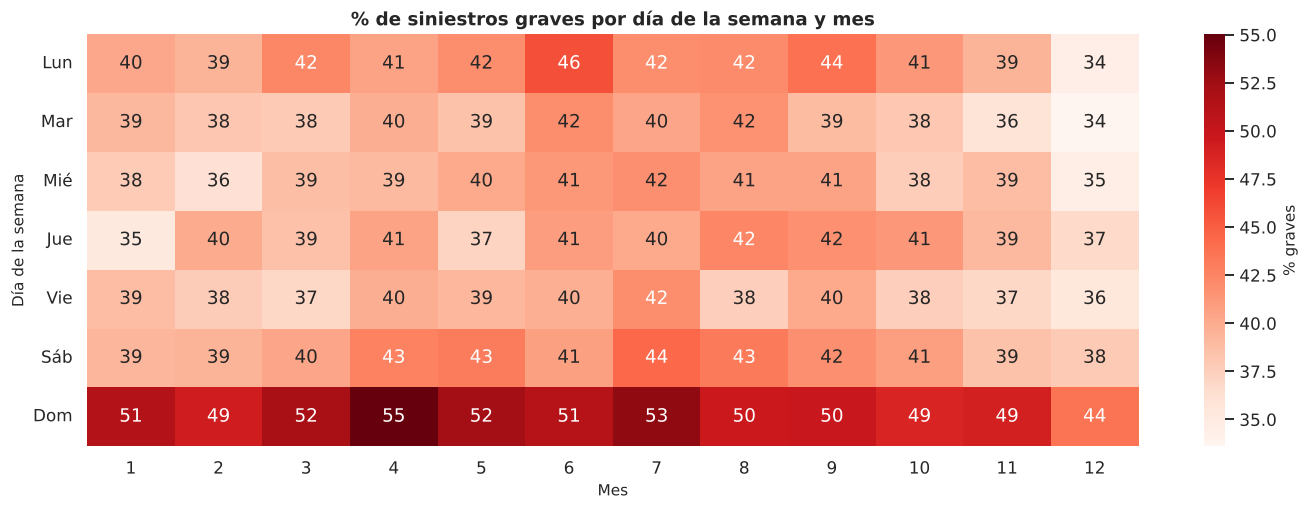

dia_semana
Lun    0.409
Mar    0.386
Mié    0.389
Jue    0.395
Vie    0.384
Sáb    0.410
Dom    0.502
Name: es_grave, dtype: float64

In [24]:
# (d) Calendario de riesgo: tasa de gravedad por mes y día de la semana
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
cal = sin.pivot_table(index="dia_semana", columns="mes", values="es_grave", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.heatmap(cal, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% graves"}, ax=ax)
ax.set_yticklabels(dias, rotation=0)
ax.set(title="% de siniestros graves por día de la semana y mes", xlabel="Mes", ylabel="Día de la semana")
fig.tight_layout(); guardar(fig, "a07_calendario"); plt.show()
sin.groupby("dia_semana").es_grave.mean().rename(index=dict(enumerate(dias))).round(3)

**Insight:** **Domingo** es el día con mayor proporción de siniestros graves, seguido del sábado: el fin de semana hay menos tráfico (menos choques simples) pero mayor velocidad y consumo de alcohol, por lo que cuando ocurre un siniestro es más probable que haya heridos. El domingo supera el 49 % de graves en casi todos los meses, mientras diciembre es el mes con menor proporción (más tráfico y más choques leves por temporada de compras). Los operativos de control de velocidad y alcoholemia deben reforzarse los domingos.

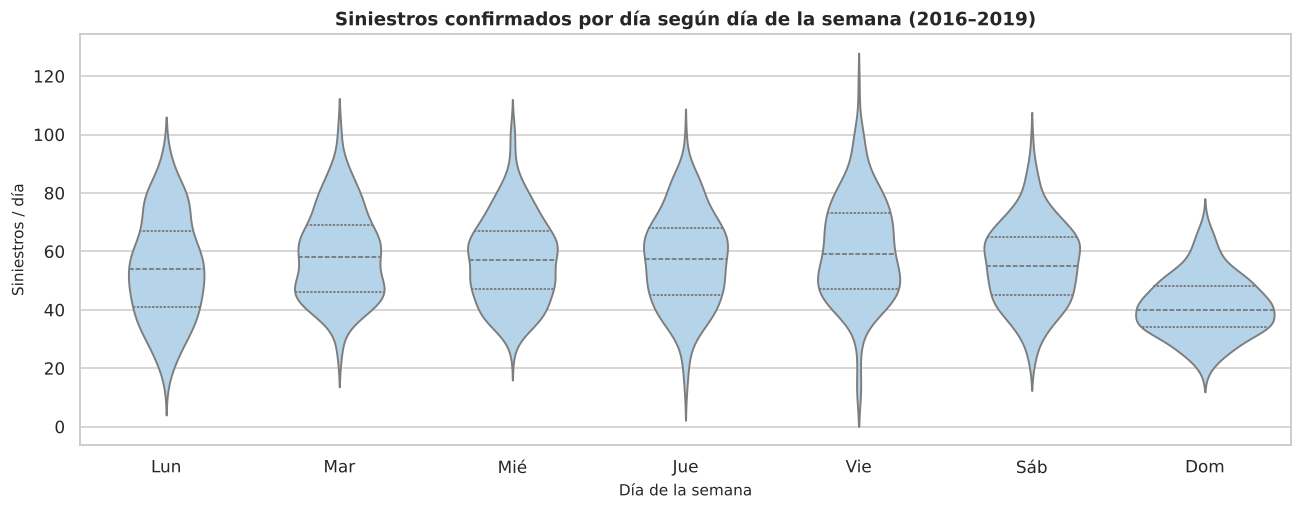

In [25]:
# (e) Violín: distribución de reportes diarios según día de la semana
diario["dia_semana"] = pd.Categorical(diario.index.dayofweek.map(dict(enumerate(dias))), categories=dias)
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.violinplot(data=diario[diario.anio <= 2019], x="dia_semana", y="siniestros", color="#AED6F1", inner="quartile", ax=ax)
ax.set(title="Siniestros confirmados por día según día de la semana (2016–2019)", xlabel="Día de la semana", ylabel="Siniestros / día")
fig.tight_layout(); guardar(fig, "a08_violin_dia"); plt.show()

**Insight:** En el periodo estable 2016–2019 los días hábiles (en especial **viernes**) concentran más siniestros, y el domingo tiene el volumen más bajo. Combinado con el gráfico anterior: entre semana hay *más* siniestros pero menos graves; el fin de semana hay *menos* siniestros pero más graves. La planeación de turnos debe considerar ambas dimensiones (volumen para agentes de tránsito, gravedad para ambulancias).

## 7. Resumen de hallazgos (lenguaje de negocio)
1. **Dos de cada tres reportes no son siniestros.** El 66 % de los reportes se confirma como *negativo*; el 34 % restante (~125 mil) son siniestros reales, de los cuales el 41 % deja lesionados o fallecidos y 3 360 dejaron fallecidos.
2. **La moto y la bicicleta definen la gravedad.** Cuando en el siniestro participa un motociclista o un ciclista, la mayoría termina con heridos o muertos; los choques entre carros casi nunca. Es la señal más fuerte para predecir gravedad y para priorizar ambulancias.
3. **El registro cambió en 2022–2024.** Los siniestros de solo daños casi desaparecen de la base desde finales de 2022, mientras que los graves solo bajan gradualmente: la base de 2023–2024 no es comparable con la de años anteriores. Además, la clase de accidente y el medio de reporte solo se diligencian bien desde 2021. Estos problemas de calidad se tratan en la Fase B y se controlan con la variable año en los modelos.

**Continuidad con el P1:** el modelo estrella diseñado en el Proyecto 1 se reconstruyó con los datos reales (sección 2.1). Las dimensiones de tiempo y vía se conservan; lugar y actor se adaptan porque la fuente no trae comuna, barrio, género ni edad. La variable objetivo del P1 (*leve / grave / mortal*) se mantiene y se modela en la Fase C.

El documento `fase_a_hallazgos.pdf` amplía estos tres hallazgos.